# TASTY sources and grouped data analysis

Executed research analysis on real local inputs or committed aggregate reports. Historical/validation scope is labeled explicitly. No test rescoring occurs. Use the isolated repository environment plus Jupyter, pandas and matplotlib.

In [1]:
from pathlib import Path
import os, json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists()
os.chdir(ROOT)
for path in [ROOT, ROOT / 'src']:
    if str(path) not in sys.path: sys.path.insert(0, str(path))
FIGURES = ROOT / 'docs' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
def show_figure(fig, name):
    path = FIGURES / (name + '.png')
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path)))
print('Executed analysis; Python', sys.version.split()[0])
print('Only aggregate outputs and figures are retained; raw rows/weights remain ignored.')


Executed analysis; Python 3.14.2
Only aggregate outputs and figures are retained; raw rows/weights remain ignored.


## Production acquisition
Acquisition is opt-in and verifies pinned source bytes or saves a dated source receipt. Defaults preserve cached files. The analysis below is retrospective documentation executed after the study was frozen; its exploratory summaries were not used to tune a new model.

In [2]:
RUN_FETCH = False
if RUN_FETCH:
    import subprocess
    assert not Path('data/external/tasty.csv').exists(), 'Preserve cached source bytes'
    assert not Path('data/processed/tasty-time_complexity.jsonl').exists()
    subprocess.run([sys.executable,'-m','src.data.tasty','--target','time_complexity'],check=True)
print('Acquisition opt-in enabled:', RUN_FETCH)


Acquisition opt-in enabled: False


## Real TASTY inputs and source limitations
The pinned adapter strips label-bearing comments and rejects ambiguous labels. Descriptive comment signatures and normalized clones only approximate true problem families. The corpus is small and scraped; metadata declares CC-BY-3.0, with underlying source provenance caveats. Acquisition below remains opt-in.

In [3]:
data_path = Path(os.environ.get('COMPLEXITY_DATA', 'data/processed/tasty-time_complexity.jsonl'))
raw = data_path.read_bytes()
records = [json.loads(line) for line in raw.decode('utf-8').splitlines() if line.strip()]
print('Processed SHA256:', hashlib.sha256(raw).hexdigest())
frame = pd.DataFrame({'label':[r['label'] for r in records], 'characters':[len(r['code']) for r in records], 'lines':[r['code'].count(chr(10))+1 for r in records]})
summary = frame.groupby('label').agg(rows=('label','size'), median_characters=('characters','median'), median_lines=('lines','median')).sort_values('rows')
display(summary)
print('Rows:', len(frame), 'duplicate exact snippets:', pd.Series([r['code'] for r in records]).duplicated().sum())

Processed SHA256: 9c9b3be5ef829b23fb616ff840754aabfc73de90e3777fbeee3cbcfe65e5af95


,rows,median_characters,median_lines
label,,,
logn,26,839.0,1.0
constant,33,609.0,1.0
cubic,35,792.0,1.0
nlogn,127,773.0,1.0
quadratic,374,770.0,1.0
linear,787,750.0,1.0


Rows: 1382 duplicate exact snippets: 125


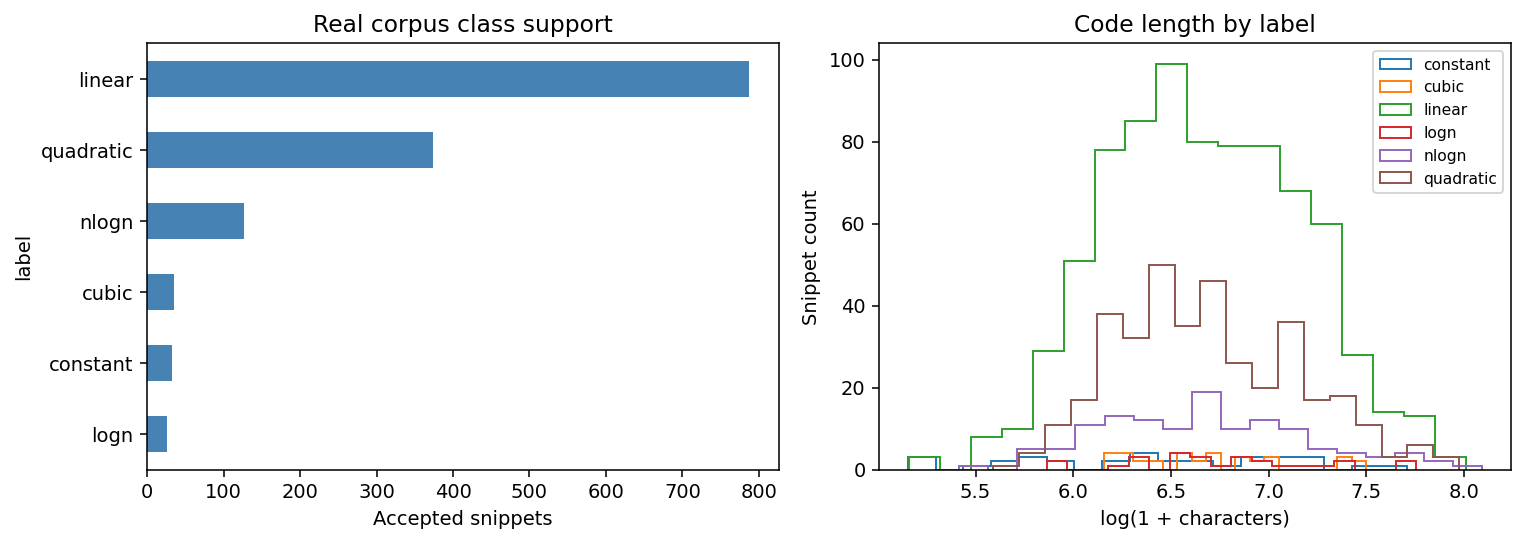

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
summary.rows.plot.barh(ax=axes[0], color='steelblue')
axes[0].set(title='Real corpus class support', xlabel='Accepted snippets')
for label, values in frame.groupby('label'):
    axes[1].hist(np.log1p(values.characters), bins=18, histtype='step', label=label)
axes[1].set(title='Code length by label', xlabel='log(1 + characters)', ylabel='Snippet count')
axes[1].legend(fontsize=8)
show_figure(fig, 'complexity_corpus_support')

## Frozen split sizes and minority support
Only counts are displayed, never source code or source-row tables. The later validation gate uses grouped OOF as well as held-out development validation; a validation spike alone is insufficient.

In [5]:
result = read_json('models/structure-v2-weights/results.json')
display(pd.DataFrame([{'split':name, 'rows':result[name+'_rows']} for name in ['train','validation','test']]))
print('Group overlap report:', result['group_overlap'])
classification = read_json('models/structure-v2-weights/evaluation.json')['classification_report']
classes = pd.DataFrame({k:v for k,v in classification.items() if isinstance(v,dict) and 'support' in v and k not in ['macro avg','weighted avg']}).T
display(classes[['support']].rename(columns={'support':'Previously observed test support'}))

,split,rows
0,train,830
1,validation,277
2,test,275


Group overlap report: 0


,Previously observed test support
constant,6.0
cubic,7.0
linear,157.0
logn,5.0
nlogn,26.0
quadratic,74.0


## Interpretation
Linear and quadratic snippets dominate; minority class evidence is limited. Code-length distributions can act as spurious shortcuts. Family grouping, source-disjoint validation and class-level metrics matter more than headline accuracy alone. No test result is used to change the already frozen procedure.